# EDA синтетических датасетов

Анализ двух итоговых наборов вопросов для книг:

- «Осуждён пожизненно»;
- «Дороги рая».

Проверяем размер и схему, пропуски и дубликаты, баланс категорий и режимов контекста, длины вопросов/ответов, число gold-чанков и простые эвристики качества. Отдельно смотрим сами EPUB: главы, чанки и в каких главах лежат gold-чанки.

In [1]:
import ast
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_colwidth", 120)

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

GOLDEN_SET_DIR = ROOT / "notebooks" / "golden_set"
DATASET_PATHS = {
    "Осуждён пожизненно": GOLDEN_SET_DIR / "osuzhden-pozhiznenno.xlsx",
    "Дороги рая": GOLDEN_SET_DIR / "dorogi-raya_finals.xlsx",
}

DATASET_PATHS

{'Осуждён пожизненно': PosixPath('/Users/trvexe/Desktop/mlsd-book-rag/notebooks/golden_set/osuzhden-pozhiznenno.xlsx'),
 'Дороги рая': PosixPath('/Users/trvexe/Desktop/mlsd-book-rag/notebooks/golden_set/dorogi-raya_finals.xlsx')}

## Загрузка и проверка схемы

Оба файла лежат в `notebooks/golden_set`. Явно проверяем наличие файлов и обязательных колонок, чтобы не получить частичный EDA.

In [2]:
REQUIRED_COLUMNS = {
    "book_title",
    "question",
    "answer",
    "chunk_ids",
    "chunks_text",
    "category",
    "context_mode",
    "is_spoiler",
    "selected_text",
    "selection_anchor_chunk_id",
    "reader_anchor_chunk_id",
    "reading_progress_char",
    "sel_start",
    "sel_end",
}

missing_files = [path for path in DATASET_PATHS.values() if not path.exists()]
if missing_files:
    missing = "\n".join(f"- {path}" for path in missing_files)
    raise FileNotFoundError(
        "Не найдены итоговые датасеты. Сначала запустите dataset_creation.ipynb:\n"
        + missing
    )

frames = []
for dataset_name, path in DATASET_PATHS.items():
    frame = pd.read_excel(path)
    missing_columns = REQUIRED_COLUMNS - set(frame.columns)
    if missing_columns:
        raise ValueError(f"{path.name}: отсутствуют колонки {sorted(missing_columns)}")
    frame = frame.copy()
    frame["dataset"] = dataset_name
    frame["source_file"] = path.name
    frames.append(frame)

df = pd.concat(frames, ignore_index=True)
print(f"Загружено {len(df)} строк из {len(frames)} файлов")
display(df.head(3))

Загружено 100 строк из 2 файлов


,book_title,question,answer,chunk_ids,chunks_text,category,context_mode,is_spoiler,selected_text,selection_anchor_chunk_id,reader_anchor_chunk_id,reading_progress_char,sel_start,sel_end,dataset,source_file
0,Осужден пожизненно,"Какое имя выбрал Ричард Дивайн, когда его задержали после смерти хозяина трактира?","Когда задержанный Ричард Дивайн ответил на вопрос трактирщика, он решительно и твердо назвал себя Руфусом Доузом, по...",['ch1-2:19'],"– Скажите, милорд, – спросил умирающего хозяин трактира, – этот человек хотел вас убить?\nЛорд Беллазис сделал одно ...",Персонажи,single,0,"Он дважды резко повторил свой вопрос, прежде чем задержанный ответил. Подняв свое бледное лицо, черты которого обрел...",ch1-2:19,ch1-2:19,20967,20280,20482,Осуждён пожизненно,osuzhden-pozhiznenno.xlsx
1,Осужден пожизненно,Почему Ричард Дивайн не решился сразу заявить о своей личности и родстве сэру Ричарду Дивайну в момент встречи?,"Ричард опасался, что признание приведет к позору матери и гибели сэра Ричарда, так как он понимал, что отец может от...","['ch1-2:14', 'ch1-2:18']","Вечером 3 мая 1827 года лорд Беллазис присутствовал на голубиных состязаниях в Хорнси-Вуде и, отделавшись от назойли...",Мотивы и смысл,scattered,0,"И сын лорда Беллазиса и леди Дивайн понял, что он очутился в положении, которое вынуждало его либо пожертвовать собо...",ch1-2:18,ch1-2:18,19807,19078,19417,Осуждён пожизненно,osuzhden-pozhiznenno.xlsx
2,Осужден пожизненно,"Какова была причина смерти сэра Дивайна перед тем, как его завещание было изменено?","Сэр Дивайн скончался от апоплексического удара, который, по мнению собеседников, произошел от ярости, когда он пытал...",['ch1-5:5'],"– А как случилось, что деньги все же достались сыну сэра Дивайна?\n– А вот как: старый Дивайн послал за нотариусом, ...",События и детали,single,0,"– А вот как: старый Дивайн послал за нотариусом, чтобы изменить завещание, но с ним произошел апоплексический удар, ...",ch1-5:5,ch1-5:5,6135,4801,4995,Осуждён пожизненно,osuzhden-pozhiznenno.xlsx


## Общая сводка и качество данных

In [3]:
def normalized_text(series: pd.Series) -> pd.Series:
    return (
        series.fillna("")
        .astype(str)
        .str.casefold()
        .str.replace(r"\s+", " ", regex=True)
        .str.strip()
    )

summary = (
    df.groupby("dataset", observed=True)
    .agg(
        rows=("question", "size"),
        categories=("category", "nunique"),
        context_modes=("context_mode", "nunique"),
        missing_questions=("question", lambda x: x.isna().sum()),
        missing_answers=("answer", lambda x: x.isna().sum()),
    )
)

quality_rows = []
for dataset_name, group in df.groupby("dataset", observed=True):
    quality_rows.append(
        {
            "dataset": dataset_name,
            "duplicate_questions": normalized_text(group["question"]).duplicated().sum(),
            "duplicate_question_answer": pd.DataFrame(
                {
                    "q": normalized_text(group["question"]),
                    "a": normalized_text(group["answer"]),
                }
            ).duplicated().sum(),
            "empty_chunk_ids": group["chunk_ids"].isna().sum(),
            "empty_chunks_text": group["chunks_text"].isna().sum(),
        }
    )

display(summary)
display(pd.DataFrame(quality_rows).set_index("dataset"))

,rows,categories,context_modes,missing_questions,missing_answers
dataset,,,,,
Дороги рая,50,3,2,0,0
Осуждён пожизненно,50,3,2,0,0


,duplicate_questions,duplicate_question_answer,empty_chunk_ids,empty_chunks_text
dataset,,,,
Дороги рая,0,0,0,0
Осуждён пожизненно,0,0,0,0


## Баланс категорий и режимов контекста

Целевой профиль: категории примерно поровну, режимы `single/scattered` — 70/30.

category,Мотивы и смысл,Персонажи,События и детали
dataset,,,
Дороги рая,16,16,18
Осуждён пожизненно,17,16,17


context_mode,scattered,single
dataset,,
Дороги рая,15,35
Осуждён пожизненно,15,35


context_mode                         scattered  single
dataset            category                           
Дороги рая         Мотивы и смысл            4      12
                   Персонажи                 5      11
                   События и детали          6      12
Осуждён пожизненно Мотивы и смысл            5      12
                   Персонажи                 5      11
                   События и детали          5      12

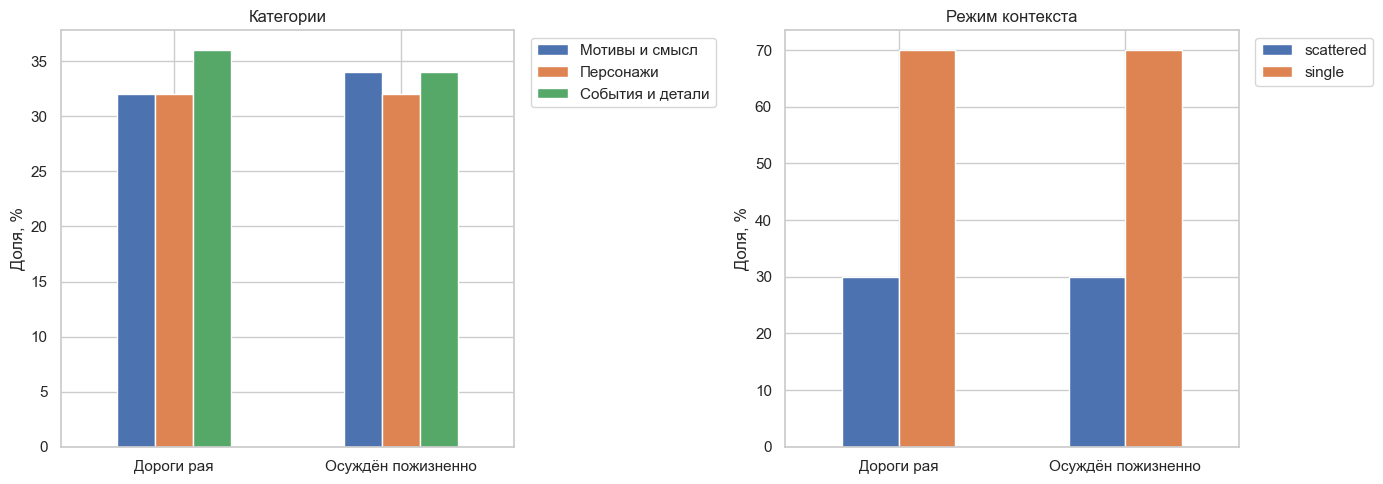

In [4]:
category_counts = pd.crosstab(df["dataset"], df["category"])
mode_counts = pd.crosstab(df["dataset"], df["context_mode"])
bucket_counts = pd.crosstab(
    [df["dataset"], df["category"]],
    df["context_mode"],
)

display(category_counts)
display(mode_counts)
display(bucket_counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
category_share = category_counts.div(category_counts.sum(axis=1), axis=0) * 100
mode_share = mode_counts.div(mode_counts.sum(axis=1), axis=0) * 100
category_share.plot(kind="bar", ax=axes[0], rot=0)
mode_share.plot(kind="bar", ax=axes[1], rot=0)
axes[0].set(title="Категории", ylabel="Доля, %", xlabel="")
axes[1].set(title="Режим контекста", ylabel="Доля, %", xlabel="")
for ax in axes:
    ax.legend(title="", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

## Длины вопросов и ответов

Для ответов ожидаем 15–35 слов; предпочтительный диапазон генерации — 20–30 слов.

,question_words_median,answer_words_min,answer_words_median,answer_words_max,allowed_share,target_share
dataset,,,,,,
Дороги рая,10.0,16,24.5,30,100.0,88.0
Осуждён пожизненно,11.5,17,24.0,30,100.0,92.0


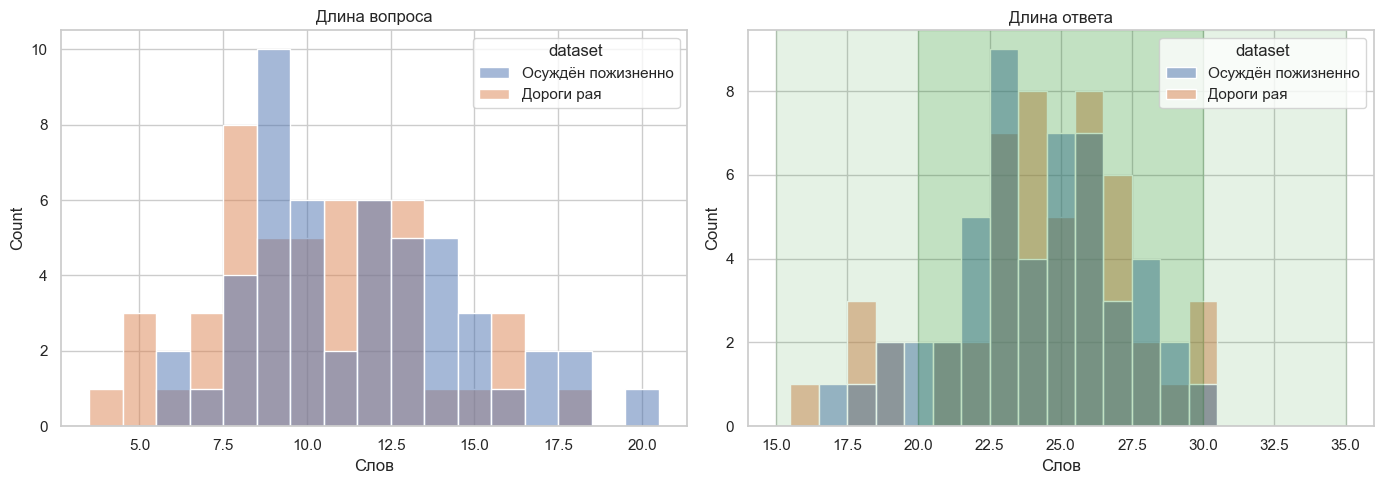

In [5]:
WORD_RE = re.compile(r"[\wЁёА-Яа-я-]+", flags=re.UNICODE)

def word_count(value: object) -> int:
    return len(WORD_RE.findall(str(value)))

df["question_words"] = df["question"].map(word_count)
df["answer_words"] = df["answer"].map(word_count)
df["answer_allowed"] = df["answer_words"].between(15, 35)
df["answer_target"] = df["answer_words"].between(20, 30)

length_summary = df.groupby("dataset", observed=True).agg(
    question_words_median=("question_words", "median"),
    answer_words_min=("answer_words", "min"),
    answer_words_median=("answer_words", "median"),
    answer_words_max=("answer_words", "max"),
    allowed_share=("answer_allowed", "mean"),
    target_share=("answer_target", "mean"),
)
length_summary[["allowed_share", "target_share"]] *= 100
display(length_summary.round(1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(data=df, x="question_words", hue="dataset", discrete=True, ax=axes[0])
sns.histplot(data=df, x="answer_words", hue="dataset", discrete=True, ax=axes[1])
axes[0].set(title="Длина вопроса", xlabel="Слов")
axes[1].axvspan(15, 35, alpha=0.1, color="green", label="допустимо 15–35")
axes[1].axvspan(20, 30, alpha=0.15, color="green", label="цель 20–30")
axes[1].set(title="Длина ответа", xlabel="Слов")
plt.tight_layout()
plt.show()

## Gold-чанки и согласованность режима

У `single` должен быть один `chunk_id`, у `scattered` — два или три.

In [6]:
def parse_list_cell(value: object) -> list[str]:
    if isinstance(value, list):
        return [str(item) for item in value]
    if pd.isna(value):
        return []
    text = str(value).strip()
    try:
        parsed = ast.literal_eval(text)
        if isinstance(parsed, (list, tuple)):
            return [str(item) for item in parsed]
    except (SyntaxError, ValueError):
        pass
    return [item.strip() for item in text.split(",") if item.strip()]

df["n_gold_chunks"] = df["chunk_ids"].map(lambda value: len(parse_list_cell(value)))
df["mode_consistent"] = np.where(
    df["context_mode"].eq("single"),
    df["n_gold_chunks"].eq(1),
    df["n_gold_chunks"].isin([2, 3]),
)

display(pd.crosstab([df["dataset"], df["context_mode"]], df["n_gold_chunks"]))
display(
    df.groupby("dataset", observed=True)["mode_consistent"]
    .agg(["sum", "count", "mean"])
    .assign(mean=lambda x: (x["mean"] * 100).round(1))
    .rename(columns={"mean": "consistent_pct"})
)

n_gold_chunks                     1  2  3
dataset            context_mode          
Дороги рая         scattered      0  6  9
                   single        35  0  0
Осуждён пожизненно scattered      0  9  6
                   single        35  0  0

,sum,count,consistent_pct
dataset,,,
Дороги рая,50,50,100.0
Осуждён пожизненно,50,50,100.0


## Поля выделения и воспроизводимость запроса (MVP)

Колонки для offline-прогона запроса **с выделением** (`selected_text`, якоря ридера, имитация прогресса). **Приёмка антиспойлера** по golden не считается: отдельный suite и детерминированные проверки `boundary_char` (design doc §2.3.1).

In [7]:
assert df.groupby("dataset")["is_spoiler"].sum().eq(25).all(), "на книгу ровно 25 is_spoiler=1"
assert ((df.groupby("dataset").size() - df.groupby("dataset")["is_spoiler"].sum()) == 25).all()
display(
    df.groupby(["dataset", "context_mode", "is_spoiler"], observed=True)
    .size()
    .unstack(fill_value=0)
)

SELECTION_COLUMNS = [
    "is_spoiler",
    "selected_text",
    "selection_anchor_chunk_id",
    "reader_anchor_chunk_id",
    "reading_progress_char",
]

empty_sel = df["selected_text"].astype(str).str.strip().eq("")
df["selection_len"] = df["selected_text"].astype(str).str.len()
df["anchors_match"] = df["selection_anchor_chunk_id"].eq(
    df["reader_anchor_chunk_id"]
)

qc = (
    df.groupby(["dataset", "context_mode"], observed=True)
    .agg(
        rows=("question", "size"),
        empty_selected_text=("selected_text", lambda s: s.astype(str).str.strip().eq("").sum()),
        selection_len_median=("selection_len", "median"),
        selection_len_max=("selection_len", "max"),
        anchors_all_match=("anchors_match", "mean"),
        progress_char_median=("reading_progress_char", "median"),
    )
    .assign(anchors_all_match=lambda x: (x["anchors_all_match"] * 100).round(1))
)
display(qc)
bounds_ok = df["sel_end"].le(df["reading_progress_char"]) & (
    df["sel_end"] - df["sel_start"]
).eq(df["selected_text"].astype(str).str.len())
print(
    f"Пустых selected_text: {empty_sel.sum()}; "
    f"расхождение якорей: {(~df['anchors_match']).sum()}; "
    f"sel_start/sel_end не сходятся: {(~bounds_ok).sum()}"
)

preview_cols = [
    "dataset",
    "context_mode",
    "question",
    *SELECTION_COLUMNS,
]
display(df[preview_cols].head(6))

is_spoiler                        0   1
dataset            context_mode        
Дороги рая         scattered      8   7
                   single        17  18
Осуждён пожизненно scattered      8   7
                   single        17  18

rows  empty_selected_text  \
dataset            context_mode                              
Дороги рая         scattered       15                    0   
                   single          35                    0   
Осуждён пожизненно scattered       15                    0   
                   single          35                    0   

                                 selection_len_median  selection_len_max  \
dataset            context_mode                                            
Дороги рая         scattered                    170.0                399   
                   single                       189.0                507   
Осуждён пожизненно scattered                    176.0                339   
                   single                       180.0                468   

                                 anchors_all_match  progress_char_median  
dataset            context_mode                                           
Дороги рая         scattered                 100.0               29621.0  
                   single                    100.0               22365.0  
Осуждён пожизненно scattered                 100.0               15446.0  
                   single                    100.0               10894.0

Пустых selected_text: 0; расхождение якорей: 0; sel_start/sel_end не сходятся: 0


,dataset,context_mode,question,is_spoiler,selected_text,selection_anchor_chunk_id,reader_anchor_chunk_id,reading_progress_char
0,Осуждён пожизненно,single,"Какое имя выбрал Ричард Дивайн, когда его задержали после смерти хозяина трактира?",0,"Он дважды резко повторил свой вопрос, прежде чем задержанный ответил. Подняв свое бледное лицо, черты которого обрел...",ch1-2:19,ch1-2:19,20967
1,Осуждён пожизненно,scattered,Почему Ричард Дивайн не решился сразу заявить о своей личности и родстве сэру Ричарду Дивайну в момент встречи?,0,"И сын лорда Беллазиса и леди Дивайн понял, что он очутился в положении, которое вынуждало его либо пожертвовать собо...",ch1-2:18,ch1-2:18,19807
2,Осуждён пожизненно,single,"Какова была причина смерти сэра Дивайна перед тем, как его завещание было изменено?",0,"– А вот как: старый Дивайн послал за нотариусом, чтобы изменить завещание, но с ним произошел апоплексический удар, ...",ch1-5:5,ch1-5:5,6135
3,Осуждён пожизненно,scattered,Почему Морис Фрер обнаружил в арестантской только четыре пары ног на нарах вместо шести?,0,– Кто здесь лежит в лазарете?\n– Не знаю.,ch1-5:23,ch1-5:23,24750
4,Осуждён пожизненно,single,"Почему Сара утверждает, что у неё нет возможности свободно проводить время с мистером Фрером?",1,"А если вы мне не нравитесь, то это уж не ваша вина.\n– Как это понять?\n– А так, что у вас, военных, много всяких об...",ch1-9:5,ch1-9:5,5850
5,Осуждён пожизненно,scattered,Какие меры предосторожности предпринял Викерс в шесть часов вечера для обеспечения безопасности тюрьмы?,1,Глава 8\n\nОПАСНЫЙ КРИЗИС,ch1-9:0,ch1-9:0,23


## Структура книг и положение gold-чанков

Баланс категорий и длина ответов задаются квотами генератора. Ниже — свойства EPUB при том же сплите, что у golden set (`chunk_size=1500`, `chunk_overlap=300`): число глав и чанков, длина чанка и **в каких главах лежат gold-чанки**.

Номер главы — порядок документа в `spine`, с 1. Один gold-чанк, на который ссылаются несколько вопросов, считается столько раз, сколько ссылок: так видно, на каких местах книги вообще проверяется граница антиспойлера.

,chapters,chunks,chunk_len_min,chunk_len_p50,chunk_len_mean,chunk_len_max
dataset,,,,,,
Осуждён пожизненно,49,969,6,1293,1105,1499
Дороги рая,19,722,102,1395,1333,1498


,gold_mentions,unique_gold_chunks,covered_chapters,chapters,uncovered_chapters
dataset,,,,,
Дороги рая,74,69,17,19,2
Осуждён пожизненно,71,67,31,49,18


,dataset,chapter,gold_chunks
13,Дороги рая,16,13
14,Дороги рая,17,10
6,Дороги рая,7,8
34,Осуждён пожизненно,28,6
35,Осуждён пожизненно,30,6
38,Осуждён пожизненно,37,5


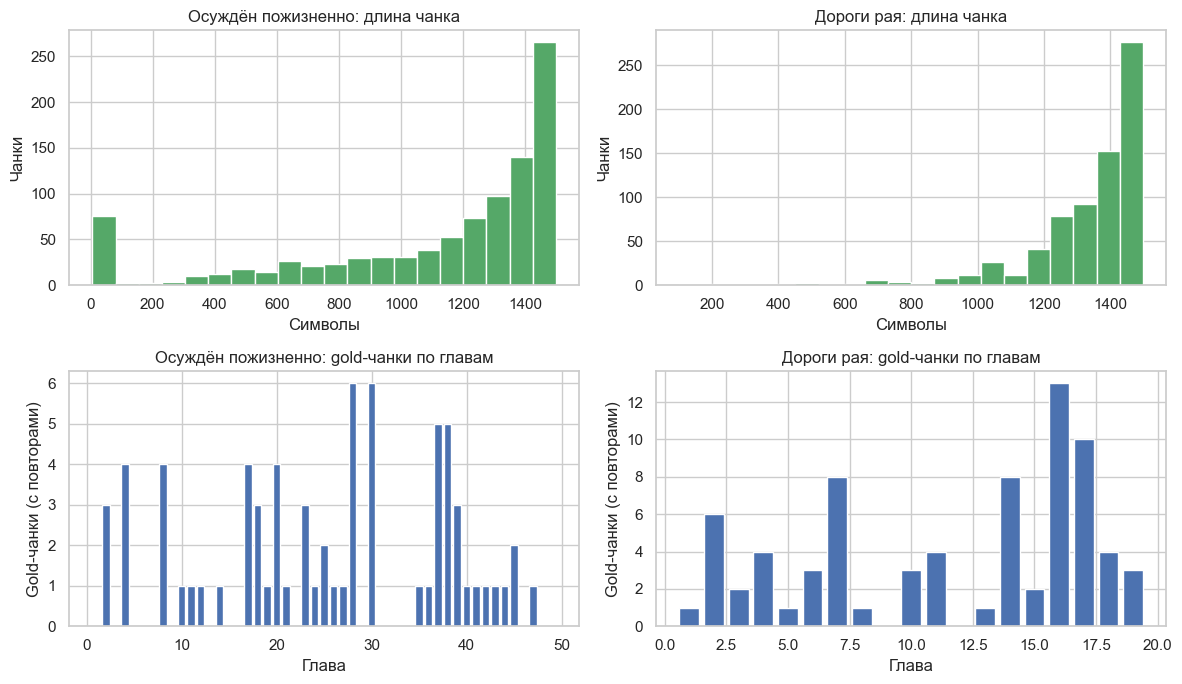

Дороги рая: максимум в главе 16 — 13 из 74 (18%)
Осуждён пожизненно: максимум в главе 28 — 6 из 71 (8%)


In [8]:
import sys

sys.path.insert(0, str(ROOT / "notebooks"))
from scripts.chunking import load_epub_chapters, split_epub

EPUB_PATHS = {
    "Осуждён пожизненно": ROOT / "notebooks" / "epubs" / "osuzhden-pozhiznenno.epub",
    "Дороги рая": ROOT / "notebooks" / "epubs" / "dorogi-raya.epub",
}
CHUNK_SIZE = 1500
CHUNK_OVERLAP = 300


def parse_chunk_ids(value):
    if isinstance(value, list):
        return value
    return ast.literal_eval(value)


book_rows = []
gold_rows = []
length_by_book = {}
for dataset_name, epub_path in EPUB_PATHS.items():
    chapters = load_epub_chapters(epub_path)
    chunks = split_epub(
        epub_path, chunk_size=CHUNK_SIZE, chunk_overlap=CHUNK_OVERLAP
    )
    by_id = {chunk.chunk_id: chunk for chunk in chunks}
    lengths = pd.Series([len(chunk.text) for chunk in chunks])
    length_by_book[dataset_name] = lengths
    book_rows.append(
        {
            "dataset": dataset_name,
            "chapters": len(chapters),
            "chunks": len(chunks),
            "chunk_len_min": int(lengths.min()),
            "chunk_len_p50": int(lengths.median()),
            "chunk_len_mean": round(float(lengths.mean())),
            "chunk_len_max": int(lengths.max()),
        }
    )
    part = df[df["dataset"] == dataset_name]
    for raw in part["chunk_ids"]:
        for chunk_id in parse_chunk_ids(raw):
            chunk = by_id[chunk_id]
            gold_rows.append(
                {
                    "dataset": dataset_name,
                    "chapter": chunk.chapter_index + 1,
                    "chunk_id": chunk_id,
                    "chunk_len": len(chunk.text),
                }
            )

book_summary = pd.DataFrame(book_rows).set_index("dataset")
display(book_summary)

gold_df = pd.DataFrame(gold_rows)
coverage = (
    gold_df.groupby("dataset")
    .agg(
        gold_mentions=("chunk_id", "size"),
        unique_gold_chunks=("chunk_id", "nunique"),
        covered_chapters=("chapter", "nunique"),
    )
    .join(book_summary[["chapters"]])
)
coverage["uncovered_chapters"] = coverage["chapters"] - coverage["covered_chapters"]
display(coverage)

chapter_counts = (
    gold_df.groupby(["dataset", "chapter"], observed=True)
    .size()
    .rename("gold_chunks")
    .reset_index()
)
top = (
    chapter_counts.sort_values(["dataset", "gold_chunks"], ascending=[True, False])
    .groupby("dataset", group_keys=False)
    .head(3)
)
display(top)

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for col, dataset_name in enumerate(EPUB_PATHS):
    lengths = length_by_book[dataset_name]
    axes[0, col].hist(lengths, bins=20, color="#55A868")
    axes[0, col].set_title(f"{dataset_name}: длина чанка")
    axes[0, col].set_xlabel("Символы")
    axes[0, col].set_ylabel("Чанки")

    counts = chapter_counts[chapter_counts["dataset"] == dataset_name]
    n_chapters = int(book_summary.loc[dataset_name, "chapters"])
    full = (
        counts.set_index("chapter")["gold_chunks"]
        .reindex(range(1, n_chapters + 1), fill_value=0)
    )
    axes[1, col].bar(full.index, full.values, color="#4C72B0")
    axes[1, col].set_title(f"{dataset_name}: gold-чанки по главам")
    axes[1, col].set_xlabel("Глава")
    axes[1, col].set_ylabel("Gold-чанки (с повторами)")
fig.tight_layout()
plt.show()

peak = coverage.copy()
for dataset_name, part in chapter_counts.groupby("dataset"):
    row = part.loc[part["gold_chunks"].idxmax()]
    mentions = int(coverage.loc[dataset_name, "gold_mentions"])
    print(
        f"{dataset_name}: максимум в главе {int(row.chapter)} — "
        f"{int(row.gold_chunks)} из {mentions} "
        f"({100 * row.gold_chunks / mentions:.0f}%)"
    )


## Выводы EDA

### Состав и объём

- В анализе **2 книги × 50 вопросов = 100 пар вопрос–ответ**.
- Пропусков и повторяющихся вопросов нет.
- Набор небольшой и покрывает только две русскоязычные книги, поэтому он подходит для первичного offline-сравнения и регрессии, но недостаточен для выводов о качестве на произвольных EPUB.

### Баланс

- В обеих книгах выдержано целевое соотношение: **35 single / 15 scattered (70/30)**.
- «Осуждён пожизненно»: категории **16/17/17**, а каждая scattered-корзина содержит ровно 5 вопросов.
- «Дороги рая»: категории **16/18/16**; есть небольшой сдвиг на один вопрос между scattered-корзинами («События» 6, «Мотивы» 4). Для выборки из 50 строк отклонение приемлемо, но его нужно контролировать при расширении.

### Выделение и воспроизводимость

- У всех строк заполнены `selected_text`, `sel_start`, `sel_end`, `selection_anchor_chunk_id`, `reader_anchor_chunk_id`, `reading_progress_char`. `sel_end` не позже прогресса, длина отрезка совпадает с `selected_text`.
- `reader_anchor_chunk_id` дублирует якорь разметки (позиция «последнего» gold-чанка для `scattered`).
- Набор из двух книг — **подвыборка**; поля нужны для **сквозного воспроизведения** запроса с выделением, а не как полный антиспойлер-eval.

### Книги и gold-чанки

- Сплит тот же, что у разметки: `chunk_size=1500`, `chunk_overlap=300`.
- «Осуждён пожизненно»: **49 глав**, **969 чанков**; медиана длины чанка около **1300** символов. Gold-чанки попадают в **31 из 49** глав; сильнее всего главы 28 и 30 — по **6 из 71** ссылки (около 8% каждая).
- «Дороги рая»: **19 глав**, **722 чанка**; медиана длины около **1400** символов. Покрыты **17 из 19** глав, но **13 из 74** ссылок (18%) сидят в **главе 16**. Антиспойлер на этой книге в основном проверяется в конце текста, а не равномерно по главам.
